   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

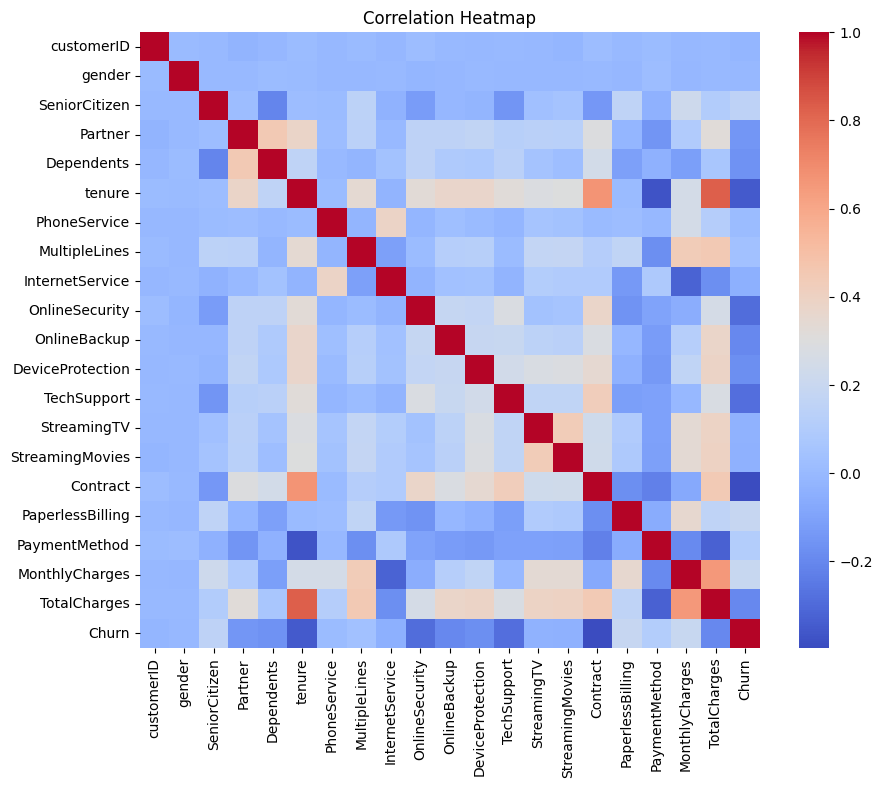

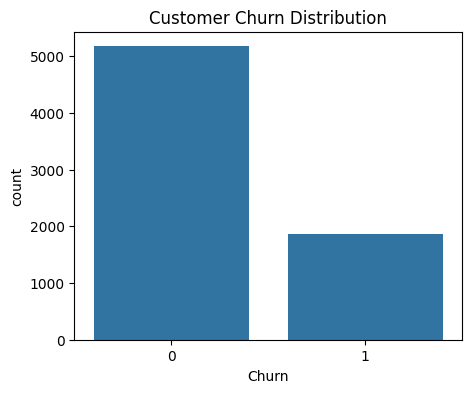

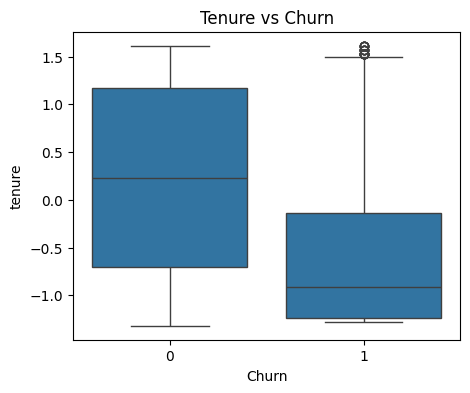


 Logistic Regression
Accuracy: 0.8176011355571328
              precision    recall  f1-score   support

           0       0.86      0.90      0.88      1036
           1       0.68      0.58      0.63       373

    accuracy                           0.82      1409
   macro avg       0.77      0.74      0.75      1409
weighted avg       0.81      0.82      0.81      1409


 Decision Tree
Accuracy: 0.7246273953158269
              precision    recall  f1-score   support

           0       0.82      0.80      0.81      1036
           1       0.48      0.51      0.49       373

    accuracy                           0.72      1409
   macro avg       0.65      0.65      0.65      1409
weighted avg       0.73      0.72      0.73      1409


 Random Forest
Accuracy: 0.7970191625266146
              precision    recall  f1-score   support

           0       0.83      0.91      0.87      1036
           1       0.66      0.47      0.55       373

    accuracy                           0.

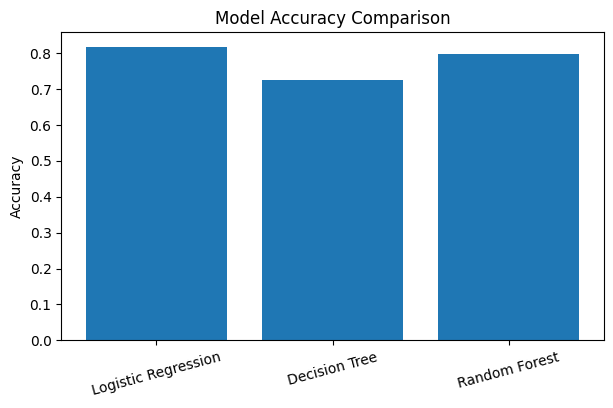

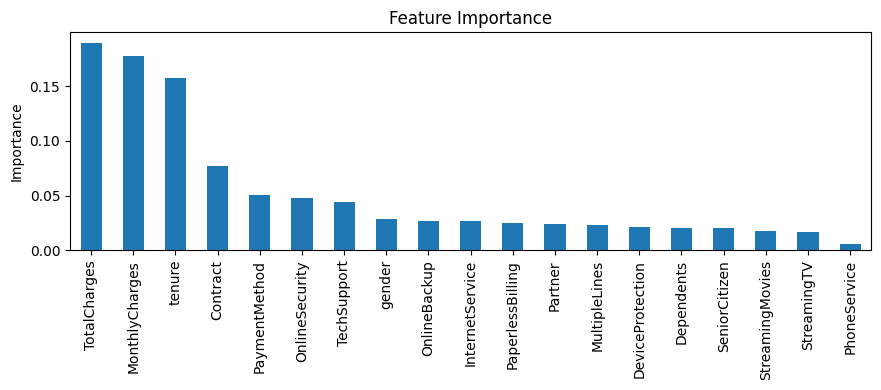

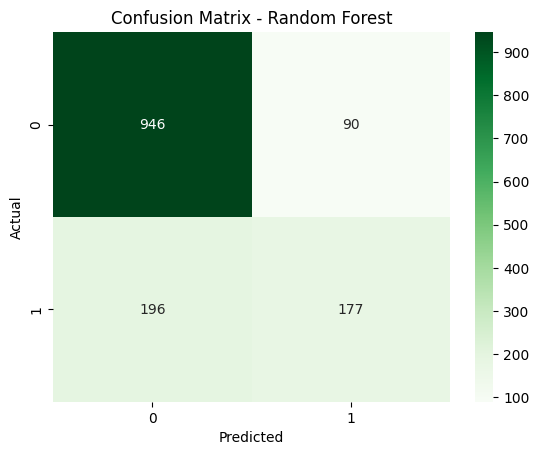


Practical Completed Successfully!


In [10]:

# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 2. Load dataset
data = pd.read_csv("Telecom_Customer_Churn.csv")

# 3. Inspect data
print(data.head())
print(data.tail())
print(data.shape)
print(data.columns)
data.info()
print(data.describe())

# 4. Check missing values
print("\nMissing Values:")
print(data.isnull().sum())

# 5. Remove duplicate rows
data.drop_duplicates(inplace=True)

# 6. Clean TotalCharges if the column exists
if "TotalCharges" in data.columns:
    data["TotalCharges"] = pd.to_numeric(
        data["TotalCharges"], errors="coerce"
    )

# 7. Fill missing values
for col in data.columns:
    if data[col].dtype == "object":
        data[col] = data[col].fillna(
            data[col].mode()[0] if not data[col].mode().empty else "Unknown"
        )
    else:
        data[col] = data[col].fillna(data[col].median())

# 8. Convert categorical data into numbers
from sklearn.preprocessing import LabelEncoder, StandardScaler

for col in data.select_dtypes(include="object").columns:
    data[col] = LabelEncoder().fit_transform(data[col])

# 9. Scale numerical columns
cols = ["tenure", "MonthlyCharges", "TotalCharges"]
cols = [col for col in cols if col in data.columns]

scaler = StandardScaler()
data[cols] = scaler.fit_transform(data[cols])

print("\nCleaned Data:")
print(data.head())
print(data.dtypes)

# 10. Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(data.corr(), cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()

# 11. Churn distribution
plt.figure(figsize=(5, 4))
sns.countplot(x="Churn", data=data)
plt.title("Customer Churn Distribution")
plt.show()

# 12. Tenure vs Churn
plt.figure(figsize=(5, 4))
sns.boxplot(x="Churn", y="tenure", data=data)
plt.title("Tenure vs Churn")
plt.show()

# 13. Separate features and target
X = data.drop("Churn", axis=1)
y = data["Churn"]

# Remove customer ID if present
for col in X.columns:
    if col.lower() in ["customerid", "customer_id"]:
        X = X.drop(col, axis=1)

# 14. Split data
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 15. Create machine learning models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

# 16. Train and evaluate models
from sklearn.metrics import accuracy_score, classification_report

results = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    results[name] = accuracy_score(y_test, pred)

    print("\n", name)
    print("Accuracy:", results[name])
    print(classification_report(y_test, pred, zero_division=0))

# 17. Compare model accuracy
plt.figure(figsize=(7, 4))
plt.bar(results.keys(), results.values())
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.xticks(rotation=15)
plt.show()

# 18. Feature importance
rf = models["Random Forest"]

importance = pd.Series(
    rf.feature_importances_, index=X.columns
).sort_values(ascending=False)

importance.plot(kind="bar", figsize=(9, 4))
plt.title("Feature Importance")
plt.ylabel("Importance")
plt.tight_layout()
plt.show()

# 19. Confusion matrix
from sklearn.metrics import confusion_matrix

pred = rf.predict(X_test)
cm = confusion_matrix(y_test, pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Greens")
plt.title("Confusion Matrix - Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

# 20. Save cleaned data
data.to_csv("cleaned_telecom_data.csv", index=False)

print("\nPractical Completed Successfully!")
